# TP Integrador – Síntesis de Redes Activas (FCEFyN – UNC)
**Punto 4 del informe: Análisis circuital simbólico** · Grupo 1 · Filtro pasabajos Butterworth $N=3$ ($f_p = 1$ kHz, $f_s = 4$ kHz)

Estructura del notebook (igual que el informe):

| Bloque | Contenido | Informe |
|---|---|---|
| 1 | Instalación e importaciones | – |
| 2 | Esquemático con Lcapy (se compila con LaTeX) | 4.1, Fig. 7 |
| 3 | Ecuaciones nodales y resolución con SymPy | 4.2 y 4.3 |
| 4 | Identificación de $\omega_0$, $Q$ y ganancias | 4.4 |
| 5 | Comparación con $H_t(s)$ (SciPy): tabla y Bode | Tabla 1, Fig. 8 |

## Bloque 1 · Instalación e importaciones

In [25]:
   # Instalar dependencias del sistema
  !apt-get update -qq
  !apt-get install -y -qq \
       texlive-latex-base \
       texlive-latex-recommended \
       texlive-latex-extra \
       texlive-pictures \
       texlive-fonts-recommended \
       cm-super \
       dvipng \
       ghostscript \
       poppler-utils
   # Instalar Lcapy
   %pip install -q lcapy

   import sys, shutil, subprocess

if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lcapy"], check=False)
    if shutil.which("pdflatex") is None:
        subprocess.run("apt-get update -qq && apt-get install -y -qq texlive-latex-recommended "
                       "texlive-latex-extra texlive-pictures poppler-utils", shell=True, check=False)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [24]:

import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display, Math
from lcapy import Circuit

def mostrar(titulo, expr):
    """Muestra 'titulo = expr' en LaTeX."""
    display(Math(titulo + " = " + sp.latex(expr)))

## Bloque 2 · Esquemático con Lcapy (Fig. 7)

Cada amplificador operacional se modela con `E out gnd opamp in+ in- A`. Los seguidores de tensión se arman
uniendo la salida con la entrada inversora mediante cables `W` (así se ve el **lazo de realimentación**).
Los nodos con nombre (`Vp1`, `Vo1`, `Va`, `Vb`, `Vo`) son los del análisis nodal.

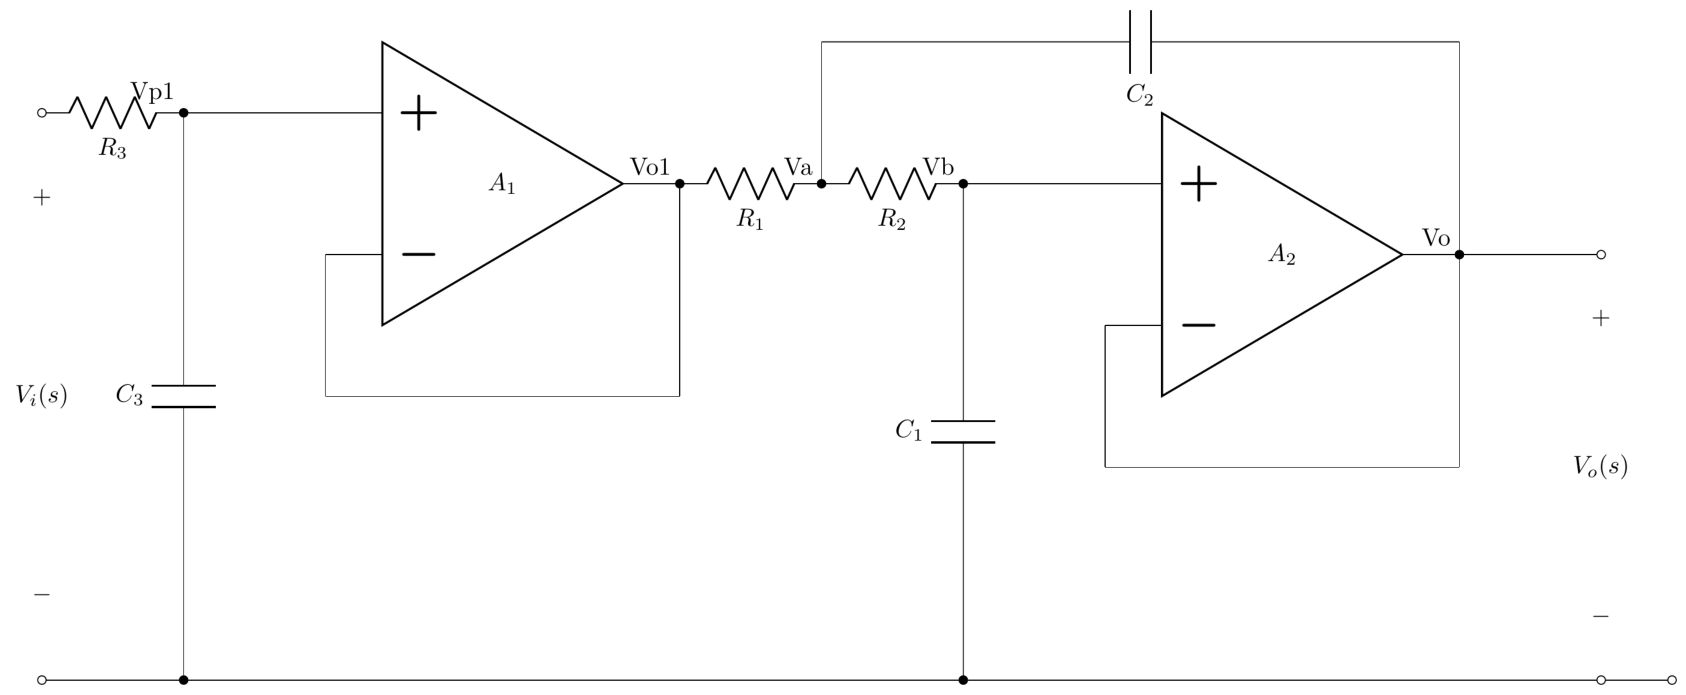

In [13]:
netlist = """
P1 1 0_1; down=3, v_=V_i(s)
R3 1 Vp1; right
C3 Vp1 0_2; down=3
W Vp1 3; right
E1 Vo1 0_4 opamp 3 5 A_1; right
W 5 5_1; down
W 5_1 4_1; right
W Vo1 4_1; down
R1 Vo1 Va; right
R2 Va Vb; right
C1 Vb 0_7; down=3
W Vb 8; right
E2 Vo 0_9 opamp 8 10 A_2; right
W 10 10_1; down
W 10_1 9_1; right
W Vo 9_1; down
W Va 6_1; up
C2 6_1 9_2; right
W 9_2 Vo; down
W Vo 11; right
P2 11 0_11; down=3, v^=V_o(s)
W 0_1 0_2; right
W 0_2 0_7; right
W 0_7 0_11; right
W 0_11 0; right=0.5
; draw_nodes=connections, label_nodes=alpha
"""

cct = Circuit(netlist)
cct.draw()                                 # se muestra aquí (compila con LaTeX)
cct.draw('circuito_cascada.tex')           # código circuitikz para Overleaf
cct.draw('circuito_cascada.png')           # imagen para el informe

## Bloque 3 · Ecuaciones nodales y resolución simbólica (§4.2 y §4.3)

Amplificadores ideales: $V^+ = V^-$ y corrientes de entrada nulas. Cada AO es no inversor con ganancia $K_i$, o sea $V_{out} = K_i V^+$ ($K_i = 1$ es el seguidor).

In [14]:
# Símbolos
s = sp.symbols('s')
Vi, Vp1, Vo1, Va, Vb, Vo = sp.symbols('V_i V_p1 V_o1 V_a V_b V_o')
R1, R2, R3, C1, C2, C3, K1, K2 = sp.symbols('R_1 R_2 R_3 C_1 C_2 C_3 K_1 K_2', positive=True)

def normalizar(H):
    """Devuelve (numerador, denominador) con el denominador mónico (coef. principal = 1)."""
    num, den = sp.fraction(H)
    c = sp.Poly(den, s).LC()
    coefs = sp.Poly(sp.expand(den / c), s).all_coeffs()          # [1, ..., término independiente]
    den_m = sum(sp.together(cf) * s**(len(coefs) - 1 - i) for i, cf in enumerate(coefs))
    return sp.simplify(num / c), den_m

def mostrar_H(titulo, num, den):
    display(Math(titulo + r" = \frac{" + sp.latex(num) + "}{" + sp.latex(den) + "}"))

In [15]:
# ---- Sección 1: primer orden (R3, C3 + AO1) ----
eq1 = sp.Eq((Vp1 - Vi)/R3 + s*C3*Vp1, 0)     # LCK en Vp1          (27)
eq2 = sp.Eq(Vo1, K1*Vp1)                      # AO1 ideal           (29)
sol = sp.solve([eq1, eq2], (Vp1, Vo1))
Hc1 = sp.simplify(sol[Vo1] / Vi)

num1, den1 = normalizar(Hc1)
mostrar_H(r"H_{c1}(s)", num1, den1)           # ecuación (34)
mostrar_H(r"H_{c1}(s)\big|_{K_1=1}", num1.subs(K1, 1), den1)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [16]:
# ---- Sección 2: Sallen-Key (R1, R2, C1 a masa, C2 realimentado + AO2) ----
eq1 = sp.Eq((Va - Vo1)/R1 + (Va - Vb)/R2 + s*C2*(Va - Vo), 0)   # LCK en Va   (30)
eq2 = sp.Eq((Vb - Va)/R2 + s*C1*Vb, 0)                           # LCK en Vb   (31)
eq3 = sp.Eq(Vo, K2*Vb)                                           # AO2 ideal   (33)
sol = sp.solve([eq1, eq2, eq3], (Va, Vb, Vo))
Hc2 = sp.simplify(sol[Vo] / Vo1)

num2, den2 = normalizar(Hc2)
mostrar_H(r"H_{c2}(s)", num2, den2)           # ecuación (35)
mostrar_H(r"H_{c2}(s)\big|_{K_2=1}", num2.subs(K2, 1), den2.subs(K2, 1))   # (36)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [17]:
# ---- Transferencia total en cascada (37) ----
Hc = (num1/den1) * (num2/den2)
mostrar(r"H_c(s) = H_{c1}(s)\,H_{c2}(s)", Hc)

Hc_K1 = Hc.subs({K1: 1, K2: 1})               # seguidores de tensión
mostrar(r"H_c(s)\big|_{K_1=K_2=1}", sp.simplify(Hc_K1))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Bloque 4 · Identificación de $\omega_0$, $Q$ y ganancias (§4.4)

Se igualan los coeficientes del denominador mónico con la forma estándar:

- 1.er orden: $s + \omega_{01}$
- 2.º orden: $s^2 + \dfrac{\omega_{02}}{Q}\,s + \omega_{02}^2$

In [18]:
# Etapa 1
w01 = den1.coeff(s, 0)                         # den1 = s + w01
G1 = sp.simplify(num1/den1).subs(s, 0)         # ganancia en continua

# Etapa 2
a1 = sp.simplify(den2.coeff(s, 1))             # = w02/Q
a0 = sp.simplify(den2.coeff(s, 0))             # = w02^2
w02 = sp.powsimp(sp.sqrt(a0), force=True)
Q = sp.simplify(sp.powsimp(w02 / a1, force=True))
G2 = sp.simplify(num2/den2).subs(s, 0)

R = sp.symbols('R', positive=True)
caso = {K2: 1, R1: R, R2: R}                   # seguidor y R1 = R2 = R
w02_part = sp.simplify(w02.subs(caso))
Q_part = sp.simplify(sp.powsimp(Q.subs(caso), force=True))

mostrar(r"\omega_{01}", w01);   mostrar(r"H_{c1}(0)", G1)
mostrar(r"\omega_{02}", w02);   mostrar(r"H_{c2}(0)", G2)
mostrar(r"Q", Q)
mostrar(r"\omega_{02}\ (K_2=1,\,R_1=R_2=R)", w02_part)
mostrar(r"Q\ (K_2=1,\,R_1=R_2=R)", Q_part)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Bloque 5 · Comparación con la función objetivo $H_t(s)$ (§3 y §4.4)

**Objetivo $H_t(s)$ (SciPy):** Butterworth pasabajos, $f_p=1$ kHz, $f_s=4$ kHz, $A_p=1$ dB, $A_s=24$ dB.

In [19]:
fp, fs = 1000, 4000
wp, ws = 2*np.pi*fp, 2*np.pi*fs
N, Wn = signal.buttord(wp, ws, 1, 24, analog=True)          # orden y frecuencia de diseño
b, a = signal.butter(N, Wn, 'low', analog=True)             # Ht(s) = b/a
z, p, k = signal.butter(N, Wn, 'low', analog=True, output='zpk')

print(f"Orden N = {N}   |   Wn = {Wn:.2f} rad/s   |   k = {k:.4e}")
print("Polos:", np.round(p, 2))

Orden N = 3   |   Wn = 7870.17 rad/s   |   k = 4.8747e+11
Polos: [-3935.08+6815.77j -7870.17   -0.j   -3935.08-6815.77j]


**Componentes** (§3.1): se fija $C_3 = 10$ nF, $C_1 = 4{,}7$ nF, $C_2 = 18$ nF y se calculan las resistencias
con $R_3 = 1/(W_n C_3)$ y $R = 1/(W_n\sqrt{C_1 C_2})$. Luego se adoptan valores comerciales.

In [20]:
C3v, C1v, C2v = 10e-9, 4.7e-9, 18e-9
R3_ideal = 1 / (Wn * C3v)                       # (20)  -> 12.71 kΩ
R_ideal  = 1 / (Wn * np.sqrt(C1v * C2v))        # (24)  -> 13.81 kΩ
print(f"R3 ideal = {R3_ideal/1e3:.2f} kΩ    R ideal = {R_ideal/1e3:.2f} kΩ")

ideales = {R3: R3_ideal, C3: C3v, R1: R_ideal, R2: R_ideal, C1: C1v, C2: C2v, K1: 1, K2: 1}
comerciales = {R3: 12.7e3, C3: C3v, R1: 13e3, R2: 13e3, C1: C1v, C2: C2v, K1: 1, K2: 1}

def valor(expr, valores):
    return float(expr.subs(valores))

R3 ideal = 12.71 kΩ    R ideal = 13.81 kΩ


In [21]:
# Tabla 1: parámetros simbólicos evaluados con los componentes comerciales vs. objetivo
filas = [
    ("Frecuencia polo real (Etapa 1) [rad/s]", "w01", Wn, valor(w01, comerciales)),
    ("Ganancia DC (Etapa 1)",                    "K1",  1.0, valor(G1, comerciales)),
    ("Frecuencia natural (Etapa 2) [rad/s]",    "w02", Wn, valor(w02, comerciales)),
    ("Factor de calidad (Etapa 2)",              "Q",   1.0, valor(Q, comerciales)),
    ("Ganancia DC (Etapa 2)",                    "K2",  1.0, valor(G2, comerciales)),
]
tabla = pd.DataFrame(filas, columns=["Parámetro", "Símbolo", "Objetivo Ht(s)", "Hc(s) comercial"])
tabla["Error [%]"] = abs(tabla["Hc(s) comercial"] - tabla["Objetivo Ht(s)"]) / tabla["Objetivo Ht(s)"] * 100
tabla.round(4)

,Parámetro,Símbolo,Objetivo Ht(s),Hc(s) comercial,Error [%]
0,Frecuencia polo real (Etapa 1) [rad/s],w01,7870.1696,7874.0157,0.0489
1,Ganancia DC (Etapa 1),K1,1.0000,1.0000,0.0000
2,Frecuencia natural (Etapa 2) [rad/s],w02,7870.1696,8363.1804,6.2643
3,Factor de calidad (Etapa 2),Q,1.0000,0.9785,2.1508
4,Ganancia DC (Etapa 2),K2,1.0000,1.0000,0.0000


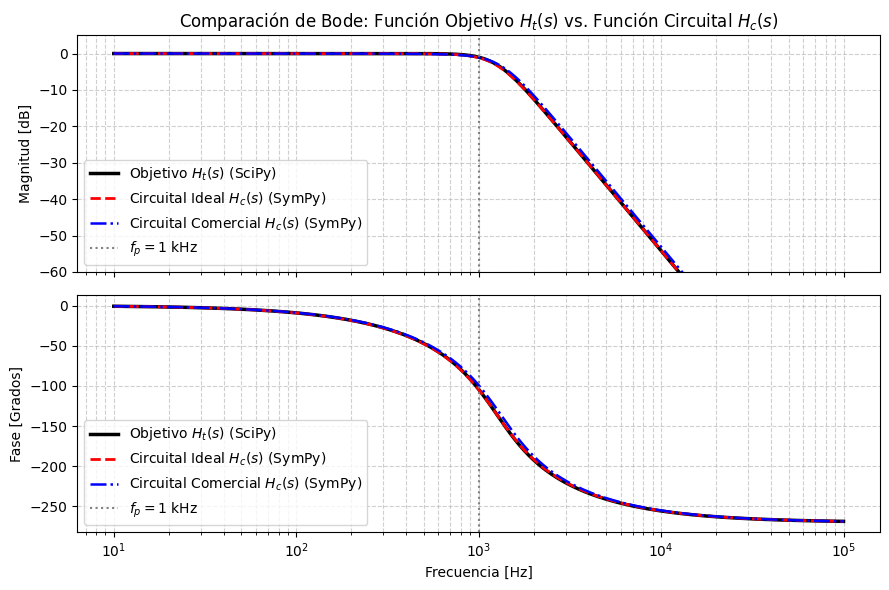

In [22]:
# Figura 8: Bode de Ht(s) (objetivo) vs. Hc(s) ideal y comercial
f = np.logspace(1, 5, 1000)
w = 2*np.pi*f

def respuesta(valores):
    """Evalúa Hc(jw) con los valores numéricos dados."""
    return sp.lambdify(s, Hc_K1.subs(valores), 'numpy')(1j*w)

H_obj = signal.freqs(b, a, w)[1]
H_id  = respuesta(ideales)
H_com = respuesta(comerciales)

mag  = lambda H: 20*np.log10(np.abs(H))
fase = lambda H: np.degrees(np.unwrap(np.angle(H)))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, g in ((ax1, mag), (ax2, fase)):
    ax.semilogx(f, g(H_obj), 'k-',  lw=2.5, label=r'Objetivo $H_t(s)$ (SciPy)')
    ax.semilogx(f, g(H_id),  'r--', lw=2,   label=r'Circuital Ideal $H_c(s)$ (SymPy)')
    ax.semilogx(f, g(H_com), 'b-.', lw=1.8, label=r'Circuital Comercial $H_c(s)$ (SymPy)')
    ax.axvline(fp, color='gray', ls=':', label=r'$f_p = 1$ kHz')
    ax.grid(True, which='both', ls='--', alpha=0.6)
    ax.legend(loc='lower left')
ax1.set_ylabel('Magnitud [dB]'); ax1.set_ylim(-60, 5)
ax1.set_title(r'Comparación de Bode: Función Objetivo $H_t(s)$ vs. Función Circuital $H_c(s)$')
ax2.set_ylabel('Fase [Grados]'); ax2.set_xlabel('Frecuencia [Hz]')
plt.tight_layout()
plt.savefig('comparacion_Ht_vs_Hc_sympy.png', dpi=300)
plt.show()